In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

In [ ]:
data_dir = Path("/Users/eyeremy/Documents/GTvate_stuff/CSV_reynoldstep/") # CHANGE TO LOAD IN CSV DATA


## READ CSV
# data = {}
# for file in data_dir.glob("*.csv"):
#     data[file.stem] = pd.read_csv(file)

## READ EXCEL

data = {}

for file in data_dir.glob("*.xlsx"):
    if file.name.startswith("~$"):
        continue 

    data[file.stem] = pd.read_excel(
        file,
        sheet_name="Samples"
    )


print(data.keys())


/Users/eyeremy/anaconda3/lib/python3.13/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/Users/eyeremy/anaconda3/lib/python3.13/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/Users/eyeremy/anaconda3/lib/python3.13/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/Users/eyeremy/anaconda3/lib/python3.13/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/Users/eyeremy/anaconda3/lib/python3.13/site-packages/openpyxl/s

dict_keys(['UUS1214_1', 'DS1212_1', 'DDS1212_1', 'US1212_2', 'US1207_1', 'UUS1213_2', 'US1214_2', 'US1211_1', 'DS1214_1', 'UUS1212_1', 'DS1213_2', 'US1213_1', 'DDS1213_2', 'US1213_2', 'DDS1213_1', 'DS1213_1', 'UUS1207_1', 'DS1214_2', 'DS1211_1', 'UUS1212_2', 'US1214_1', 'DDS1211_1', 'UUS1213_1', 'DS1207_1', 'DDS1207_1', 'DDS1212_2', 'US1212_1', 'UUS1214_2', 'UUS1211_1', 'DS1212_2'])


In [ ]:

# Extract frequencies per file
def get_freq(col):
    if isinstance(col, str) and "ǀf" in col:
        return col.split("ǀ")[1]
    return None

freq_sets = {}

for name, df in data.items():
    freqs = {
        get_freq(c)
        for c in df.columns
        if get_freq(c) is not None
    }
    freq_sets[name] = freqs


# Get full set of all frequencies across files
all_freqs = set.union(*freq_sets.values())

print(f"\nTotal unique frequencies across all files: {len(all_freqs)}")

# Check each file
for name, freqs in freq_sets.items():
    missing = all_freqs - freqs
    extra   = freqs - all_freqs

    print(f"\n{name}:")
    print(f"  num freqs = {len(freqs)}")

    if missing:
        print(f"  MISSING ({len(missing)}): {sorted(missing)}")
    else:
        print("  MISSING: None")

    if extra:
        print(f"  EXTRA: {sorted(extra)}")


Total unique frequencies across all files: 27

UUS1214_1:
  num freqs = 27
  MISSING: None

DS1212_1:
  num freqs = 27
  MISSING: None

DDS1212_1:
  num freqs = 27
  MISSING: None

US1212_2:
  num freqs = 27
  MISSING: None

US1207_1:
  num freqs = 27
  MISSING: None

UUS1213_2:
  num freqs = 27
  MISSING: None

US1214_2:
  num freqs = 27
  MISSING: None

US1211_1:
  num freqs = 27
  MISSING: None

DS1214_1:
  num freqs = 27
  MISSING: None

UUS1212_1:
  num freqs = 27
  MISSING: None

DS1213_2:
  num freqs = 27
  MISSING: None

US1213_1:
  num freqs = 27
  MISSING: None

DDS1213_2:
  num freqs = 27
  MISSING: None

US1213_2:
  num freqs = 27
  MISSING: None

DDS1213_1:
  num freqs = 27
  MISSING: None

DS1213_1:
  num freqs = 27
  MISSING: None

UUS1207_1:
  num freqs = 27
  MISSING: None

DS1214_2:
  num freqs = 27
  MISSING: None

DS1211_1:
  num freqs = 27
  MISSING: None

UUS1212_2:
  num freqs = 27
  MISSING: None

US1214_1:
  num freqs = 27
  MISSING: None

DDS1211_1:
  num fre

In [4]:
# GET FREQUENCIY COLUMNS FROM FILE

def get_freq(col):
    if "ǀf" in col:
        return col.split("ǀ")[1] 
    return None

freq_sets = []

for df in data.values():

    freqs = {
        get_freq(c)
        for c in df.columns
        if get_freq(c) is not None
    }

    freq_sets.append(freqs)

common_freqs = sorted(
    set.intersection(*freq_sets),
    key=lambda x: float(x[1:].replace("_","."))
)

print("Common freqs:", common_freqs)
print("Amount of freqs:", len(common_freqs))

Common freqs: ['f25', 'f31_5', 'f40', 'f50', 'f63', 'f80', 'f100', 'f125', 'f160', 'f200', 'f250', 'f315', 'f400', 'f500', 'f630', 'f800', 'f1000', 'f1250', 'f1600', 'f2000', 'f2500', 'f3100', 'f4000', 'f5000', 'f6300', 'f8000', 'f10000']
Amount of freqs: 27


In [5]:
for name, df in data.items():

    non_freq = [c for c in df.columns if "ǀf" not in c]

    freq_cols = [
        c for c in df.columns
        if get_freq(c) in common_freqs
    ]

    df = df[non_freq + freq_cols]

    data[name] = df

In [6]:
# SEPARATE EXPERIMENTS AND SENSORS

import re
from collections import defaultdict

grouped = defaultdict(list)

pattern = re.compile(r"([A-Z]+)(\d+)_(\d+)")

for name, df in data.items():

    m = pattern.match(name)

    probe = m.group(1)
    iteration = f"{m.group(2)}_{m.group(3)}"

    grouped[iteration].append((probe, df))

print(grouped.keys())

for k, v in grouped.items():
    print(k, [p for p,_ in v])

dict_keys(['1214_1', '1212_1', '1212_2', '1207_1', '1213_2', '1214_2', '1211_1', '1213_1'])
1214_1 ['UUS', 'DS', 'US']
1212_1 ['DS', 'DDS', 'UUS', 'US']
1212_2 ['US', 'UUS', 'DDS', 'DS']
1207_1 ['US', 'UUS', 'DS', 'DDS']
1213_2 ['UUS', 'DS', 'DDS', 'US']
1214_2 ['US', 'DS', 'UUS']
1211_1 ['US', 'DS', 'DDS', 'UUS']
1213_1 ['US', 'DDS', 'DS', 'UUS']


In [7]:
# GET RE NUMBER COLUMN

sample_df = next(iter(data.values()))

print("Columns in dataset:")
print(sample_df.columns)

re_col = next(
    c for c in sample_df.columns
    if "Re" in c or "re" in c
)

print("Using Reynolds column:", re_col)

Columns in dataset:
Index(['Date-Time', 'Reynolds_step', 'Leak Event', 'AC01-1400361ǀf100',
       'AC01-1400361ǀf1000', 'AC01-1400361ǀf10000', 'AC01-1400361ǀf125',
       'AC01-1400361ǀf1250', 'AC01-1400361ǀf160', 'AC01-1400361ǀf1600',
       'AC01-1400361ǀf200', 'AC01-1400361ǀf2000', 'AC01-1400361ǀf25',
       'AC01-1400361ǀf250', 'AC01-1400361ǀf2500', 'AC01-1400361ǀf3100',
       'AC01-1400361ǀf315', 'AC01-1400361ǀf31_5', 'AC01-1400361ǀf40',
       'AC01-1400361ǀf400', 'AC01-1400361ǀf4000', 'AC01-1400361ǀf50',
       'AC01-1400361ǀf500', 'AC01-1400361ǀf5000', 'AC01-1400361ǀf63',
       'AC01-1400361ǀf630', 'AC01-1400361ǀf6300', 'AC01-1400361ǀf80',
       'AC01-1400361ǀf800', 'AC01-1400361ǀf8000'],
      dtype='object')
Using Reynolds column: Reynolds_step


In [8]:
# SORT FREQUENCIES IN ORDER

sample_df = next(iter(data.values()))

freq_cols = [
    c for c in sample_df.columns
    if "ǀf" in c
]

freq_cols = sorted(
    freq_cols,
    key=lambda x: float(x.split("ǀf")[1].replace("_","."))
)

print("Number of frequencies:", len(freq_cols))


probe_order = ["UUS", "US", "DS", "DDS"]

Number of frequencies: 27


In [ ]:
# Sampling and dataset building code is the same as in the leak detection and baseline model...

In [ ]:
# BUILD ITERATION SETS

probe_order = ["UUS", "US", "DS", "DDS"]

iteration_probe_coords = {
    "1214_1": {
        "UUS": [-1.9177, 0.0250],
        "US":  [-0.4572, 0.0250],
        "DS":  [ 0.4572, 0.0250],
        "DDS": [ 4.1275, 0.0250],
    },
    "1212_1": {
        "UUS": [-4.1275, 0.0250],
        "US":  [-0.4572, 0.0250],
        "DS":  [ 0.4572, 0.0250],
        "DDS": [ 1.9177, 0.0250],
    },
    "1212_2": {
        "UUS": [-4.1275, 0.0250],
        "US":  [-0.4572, 0.0250],
        "DS":  [ 0.4572, 0.0250],
        "DDS": [ 1.9177, 0.0250],
    },
    "1207_1": {
        "UUS": [-3.0226, 0.0250],
        "US":  [-0.4572, 0.0250],
        "DS":  [ 0.4572, 0.0250],
        "DDS": [ 3.0226, 0.0250],
    },
    "1213_2": {
        "UUS": [-1.9177, 0.0250],
        "US":  [-0.4572, 0.0250],
        "DS":  [ 0.4572, 0.0250],
        "DDS": [ 4.1275, 0.0250],
    },
    "1214_2": {
        "UUS": [-4.1275, 0.0250],
        "US":  [-0.4572, 0.0250],
        "DS":  [ 0.4572, 0.0250],
        "DDS": [ 1.9177, 0.0250],
    },
    "1211_1": {
        "UUS": [-3.0226, 0.0250],
        "US":  [-0.4572, 0.0250],
        "DS":  [ 0.4572, 0.0250],
        "DDS": [ 3.0226, 0.0250],
    },
    "1213_1": {
        "UUS": [-1.9177, 0.0250],
        "US":  [-0.4572, 0.0250],
        "DS":  [ 0.4572, 0.0250],
        "DDS": [ 4.1275, 0.0250],
    },
}

# Add hole size per iteration
iteration_hole_sizes = {
    "1214_1": 4.0,
    "1212_1": 4.0,
    "1212_2": 4.0,
    "1207_1": 2.0,
    "1213_2": 0.8,
    "1214_2": 0.8,
    "1211_1": 2.0,
    "1213_1": 0.8,
}

continuous_iterations = {}

for iteration, probe_list in grouped.items():

    probe_values = []
    probe_coords = []

    probe_dict = {probe: df for probe, df in probe_list}
    coords_map = iteration_probe_coords.get(iteration, {})

    ref_df = next(iter(probe_dict.values()))

    ref_T = ref_df.shape[0]
    F = len(common_freqs)

    for probe in probe_order:

        if probe in probe_dict:
            df = probe_dict[probe]

            freq_cols = []
            for f in common_freqs:
                col = next(c for c in df.columns if f"ǀ{f}" in c)
                freq_cols.append(col)

            values = (
                df[freq_cols]
                .apply(pd.to_numeric, errors="coerce")
                .fillna(0.0)
                .values.astype(np.float32)
            )
        else:
            print(f"{iteration}: missing {probe}, padding zeros")
            values = np.zeros((ref_T, F), dtype=np.float32)

        probe_values.append(values)

        coord = coords_map.get(probe)
        if coord is None:
            print(f"{iteration}: missing coordinates for {probe}, padding [0,0]")
            coord = [0.0, 0.0]

        probe_coords.append(coord)

    for probe, df in probe_list:
        print(iteration, probe, df.shape)

    min_T = min(v.shape[0] for v in probe_values)

    probe_values = [v[:min_T] for v in probe_values]
    probe_values = np.stack(probe_values, axis=1)   # (T,P,F)
    probe_coords = np.array(probe_coords, dtype=np.float32)

    re_values = (
        pd.to_numeric(ref_df[re_col], errors="coerce")
        .fillna(0.0)
        .values[:min_T]
        .astype(np.float32)
    )

    # Use fixed hole size per iteration,
    hole_size = iteration_hole_sizes.get(iteration, 0.0)
    if iteration not in iteration_hole_sizes:
        print(f"{iteration}: missing hole size, defaulting to 0.0")

    leak_event = (
        pd.to_numeric(ref_df["Leak Event"], errors="coerce")
        .fillna(0.0)
        .values[:min_T]
        .astype(np.float32)
    )

    leak_event = (leak_event > 0).astype(np.float32)

    hole_values = hole_size * leak_event

    time_values = pd.to_datetime(ref_df["Date-Time"]).values[:min_T]

    continuous_iterations[iteration] = {
        "probe_values": probe_values,
        "probe_coords": probe_coords,
        "Re": re_values,
        "hole_size": hole_values,
        "flow_rate": np.zeros(min_T, dtype=np.float32),
        "time": time_values,
    }

print("Built iterations:", continuous_iterations.keys())

1214_1: missing DDS, padding zeros
1214_1 UUS (14401, 30)
1214_1 DS (14401, 30)
1214_1 US (14401, 30)
1212_1 DS (10801, 30)
1212_1 DDS (10801, 30)
1212_1 UUS (10801, 30)
1212_1 US (10801, 30)
1212_2 US (10801, 30)
1212_2 UUS (10801, 30)
1212_2 DDS (10801, 30)
1212_2 DS (10801, 30)
1207_1 US (5581, 30)
1207_1 UUS (5581, 30)
1207_1 DS (5581, 30)
1207_1 DDS (5581, 30)
1213_2 UUS (10801, 30)
1213_2 DS (10801, 30)
1213_2 DDS (10801, 30)
1213_2 US (10801, 30)
1214_2: missing DDS, padding zeros
1214_2 US (14401, 30)
1214_2 DS (14401, 30)
1214_2 UUS (14401, 30)
1211_1 US (10801, 30)
1211_1 DS (10801, 30)
1211_1 DDS (10801, 30)
1211_1 UUS (10801, 30)
1213_1 US (10801, 30)
1213_1 DDS (10801, 30)
1213_1 DS (10801, 30)
1213_1 UUS (10801, 30)
Built iterations: dict_keys(['1214_1', '1212_1', '1212_2', '1207_1', '1213_2', '1214_2', '1211_1', '1213_1'])


In [11]:
# TRAINING - EDIT FOR TESTING
train_iters = ["1211_1", "1212_2", "1213_1", "1213_2"]

# VALIDATION - EDIT FOR TESTING
val_iters = ["1212_1"]

# TESTING - EDIT FOR TESTING
test_iters = ["1207_1"]


train_data = {k: continuous_iterations[k] for k in train_iters}
val_data   = {k: continuous_iterations[k] for k in val_iters}
test_data   = {k: continuous_iterations[k] for k in test_iters}


print("Train files:", list(train_data.keys()))
print("Val files:", list(val_data.keys()))

Train files: ['1211_1', '1212_2', '1213_1', '1213_2']
Val files: ['1212_1']


In [ ]:
# DATASET BUILDER

import torch
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
import math


class PipeLeakSequenceDataset(Dataset):
    def __init__(self, continuous_iterations,
                 normalize_probes=True,
                 healthy_only=False):   # NEW FLAG

        self.samples = []

        for iteration, data in continuous_iterations.items():

            X_raw     = torch.tensor(data["probe_values"], dtype=torch.float32)
            Re_raw    = torch.tensor(data["Re"], dtype=torch.float32)
            hole_raw  = torch.tensor(data["hole_size"], dtype=torch.float32)
            flow_raw  = torch.tensor(data["flow_rate"], dtype=torch.float32)
            coords    = torch.tensor(data["probe_coords"], dtype=torch.float32)

            # HEALTHY TIMESTEP FILTER
            if healthy_only:
                mask = hole_raw == 0

                if mask.sum() == 0:
                    continue

                X_raw    = X_raw[mask]
                Re_raw   = Re_raw[mask]
                hole_raw = hole_raw[mask]
                flow_raw = flow_raw[mask]

            sample = {
                "iteration": iteration,
                "X_raw": X_raw,
                "Re_raw": Re_raw,
                "hole_raw": hole_raw,
                "flow_raw": flow_raw,
                "coords": coords,
                "datetime": data["time"] 
            }

            self.samples.append(sample)


        # Normalize targets
        self.MAX_RE = 150 #150000.0
        self.MAX_HOLE = 4.0
        self.MAX_FLOW = max(
            s["flow_raw"].max().item() for s in self.samples
        )

        for s in self.samples:
            s["Re"] = s["Re_raw"] / self.MAX_RE
            s["hole"] = s["hole_raw"] / self.MAX_HOLE
            s["flow"] = s["flow_raw"] / self.MAX_FLOW

        if normalize_probes:
            LOG_DENOM = math.log1p(60.0)

            for s in self.samples:
                X_raw = s["X_raw"]  # (T,P,F)

                X = X_raw/50 

                s["X"] = X

        else:
            for s in self.samples:
                s["X"] = s["X_raw"]


    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        s = self.samples[idx]

        X = s["X"]                      # (T, P, F)
        coords = s["coords"]             # (P, 2)
        Re = s["Re"]
        hole = s["hole"]
        flow = s["flow"]
        iteration = s["iteration"]
        datetime = s["datetime"]

        leak_open = (hole > 0).float()

        return {
            "X": X,
            "coords": coords,
            "Re": Re,
            "hole": hole,
            "flow": flow,
            "leak_open": leak_open,
            "iteration": iteration,
            "datetime": datetime 
        }


In [ ]:

train_dataset = PipeLeakSequenceDataset(train_data, normalize_probes=True, healthy_only=False)
val_dataset   = PipeLeakSequenceDataset(val_data, normalize_probes=True, healthy_only=False)
test_dataset   = PipeLeakSequenceDataset(test_data, normalize_probes=True, healthy_only=False)

In [16]:
# CHOOSE DEVICE (CPU, CUDA, etc.)

device = torch.device('mps')

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class SpectralToCurrentReModel(nn.Module):
    def __init__(
        self,
        Freq=27,
        spec_hidden_dim=64,
        lstm_hidden_dim=64,
        num_lstm_layers=1,
        dropout=0.1
    ):
        super().__init__()

        self.Freq = Freq

        self.spec_encoder = nn.Sequential(
            nn.Linear(Freq, spec_hidden_dim),
            nn.ReLU(),
            nn.Linear(spec_hidden_dim, spec_hidden_dim),
            nn.ReLU()
        )

        self.lstm = nn.LSTM(
            input_size=spec_hidden_dim,
            hidden_size=lstm_hidden_dim,
            num_layers=num_lstm_layers,
            batch_first=True,
            dropout=dropout if num_lstm_layers > 1 else 0.0
        )

        self.re_head = nn.Linear(lstm_hidden_dim, 1)

    def forward(self, X_window):

        B, W, P, Freq = X_window.shape
        assert Freq == self.Freq

        x = X_window.reshape(B * W * P, Freq)
        h = self.spec_encoder(x)

        H = h.shape[-1]
        h = h.view(B, W, P, H)

        # average across probes
        h = h.mean(dim=2)              # (B,W,H)

        h_lstm, _ = self.lstm(h)       # (B,W,H_lstm)

        h_last = h_lstm[:, -1, :]      # (B,H_lstm)

        Re_hat = self.re_head(h_last).squeeze(-1)  # (B,)

        return {"Re_hat": Re_hat}

In [ ]:
class WindowedLeakDataset(torch.utils.data.Dataset):
    def __init__(self, base_dataset, window_size=40):
        self.samples = []
        self.window_size = window_size

        for idx in range(len(base_dataset)):
            s = base_dataset[idx]

            X = s["X"]
            Re = s["Re"]
            hole = s["hole"]
            coords = s["coords"]

            X = X.squeeze(0) if X.dim() == 4 else X
            Re = Re.squeeze()
            hole = hole.squeeze()

            T = X.shape[0]

            for t_end in range(window_size, T + 1):
                Xw = X[t_end-window_size:t_end]
                Rew = Re[t_end-window_size:t_end]

                leak_label = (hole[t_end-1] > 0).float()
                hole_size = hole[t_end-1]

                self.samples.append((Xw, Rew, coords, leak_label, hole_size))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        Xw, Rew, coords, leak_label, hole_size = self.samples[idx]

        return {
            "window": Xw,
            "Re_window": Rew,
            "coords": coords,
            "leak_label": leak_label,
            "hole_size": hole_size
        }

In [19]:
def train_spectral_to_current_re_model(
    model,
    train_loader,
    val_loader,
    epochs=100,
    lr=1e-3,
    device="cpu"
):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    for ep in range(epochs):
        model.train()
        train_loss = 0.0

        for batch in train_loader:
            Xw = batch["window"].to(device).float()                  # (B,W,P,F)
            Rew = batch["Re_window"].to(device).float()

            Re_target = Rew[:, -1]                                   # (B,)

            out = model(Xw)
            Re_hat = out["Re_hat"]                                   # (B,)

            loss = F.l1_loss(Re_hat, Re_target)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

        train_loss /= len(train_loader)

        model.eval()
        val_loss = 0.0

        with torch.no_grad():
            for batch in val_loader:
                Xw = batch["window"].to(device).float()
                Rew = batch["Re_window"].to(device).float()

                Re_target = Rew[:, -1]

                out = model(Xw)
                Re_hat = out["Re_hat"]

                loss = F.l1_loss(Re_hat, Re_target)

                val_loss += loss.item()

        val_loss /= len(val_loader)

        print(
            f"Epoch {ep+1}/{epochs} | "
            f"Train Loss: {train_loss:.6f} | "
            f"Val Loss: {val_loss:.6f}"
        )

    return model

In [ ]:
train_windows = WindowedLeakDataset(train_dataset, window_size=40)
val_windows   = WindowedLeakDataset(val_dataset,   window_size=40)

train_loader = torch.utils.data.DataLoader(
    train_windows,
    batch_size=64,
    shuffle=True
)

val_loader = torch.utils.data.DataLoader(
    val_windows,
    batch_size=64,
    shuffle=False
)

re_model = SpectralToCurrentReModel(
    Freq=27,
    spec_hidden_dim=64,
    lstm_hidden_dim=64,
    num_lstm_layers=1,
    dropout=0.1
)

# UNCOMMENT TO TRAIN RE SPECTRAL MODEL

# re_model = train_spectral_to_current_re_model(
#     re_model,
#     train_loader,
#     val_loader,
#     epochs=500,
#     lr=1e-4,
#     device=device
# )

Epoch 1/500 | Train Loss: 0.128697 | Val Loss: 0.041852
Epoch 2/500 | Train Loss: 0.036615 | Val Loss: 0.036931
Epoch 3/500 | Train Loss: 0.032166 | Val Loss: 0.035248
Epoch 4/500 | Train Loss: 0.030652 | Val Loss: 0.037544
Epoch 5/500 | Train Loss: 0.029067 | Val Loss: 0.032337
Epoch 6/500 | Train Loss: 0.028518 | Val Loss: 0.034433
Epoch 7/500 | Train Loss: 0.027478 | Val Loss: 0.034364
Epoch 8/500 | Train Loss: 0.026689 | Val Loss: 0.038233
Epoch 9/500 | Train Loss: 0.026369 | Val Loss: 0.033082
Epoch 10/500 | Train Loss: 0.025644 | Val Loss: 0.034281
Epoch 11/500 | Train Loss: 0.024752 | Val Loss: 0.046374
Epoch 12/500 | Train Loss: 0.024745 | Val Loss: 0.033798
Epoch 13/500 | Train Loss: 0.024227 | Val Loss: 0.034158
Epoch 14/500 | Train Loss: 0.024005 | Val Loss: 0.035199
Epoch 15/500 | Train Loss: 0.023882 | Val Loss: 0.037001
Epoch 16/500 | Train Loss: 0.023381 | Val Loss: 0.040918
Epoch 17/500 | Train Loss: 0.023180 | Val Loss: 0.033079
Epoch 18/500 | Train Loss: 0.022488 | Va

In [ ]:
# SAVE RE MODEL... edit path for location
# torch.save(re_model.state_dict(), "/Users/eyeremy/Documents/GTvate_stuff/model/re_pred.pt")

# LOAD SAVED RE MODEL (change to where model is held)
# state_dict = torch.load("/Users/eyeremy/Documents/GTvate_stuff/model/re_pred.pt", map_location=device)
# re_model.load_state_dict(state_dict)
# re_model = re_model.to(device)

In [ ]:
# Simple inference code

@torch.no_grad()
def run_full_sequence_re_model(model, sample, window_size, device):
    model.eval()

    X = sample["X"].to(device).float()       # (T,P,F)
    Re = sample["Re"].to(device).float()     # (T,)
    hole = sample["hole"].to(device).float()

    datetime_seq = sample["datetime"]
    iteration = sample["iteration"]

    T, P, F = X.shape
    all_re_pred = []

    for t in range(window_size - 1, T):
        Xw = X[t - window_size + 1:t + 1].unsqueeze(0)  # (1,W,P,F)

        out = model(Xw)
        Re_hat = out["Re_hat"][0]                       # scalar

        all_re_pred.append(Re_hat.cpu())

    Re_pred = torch.stack(all_re_pred)

    return {
        "iteration": iteration,
        "datetime": datetime_seq[window_size - 1:],
        "Re_pred": Re_pred,
        "Re_true": Re[window_size - 1:].cpu(),
        "hole": hole[window_size - 1:].cpu(),
        "X_true": X[window_size - 1:].cpu()
    }


In [ ]:
sample = val_dataset[0] # Chnage to look at training or testing data
window_size = 40

re_results = run_full_sequence_re_model(
    re_model,
    sample,
    window_size,
    device
)

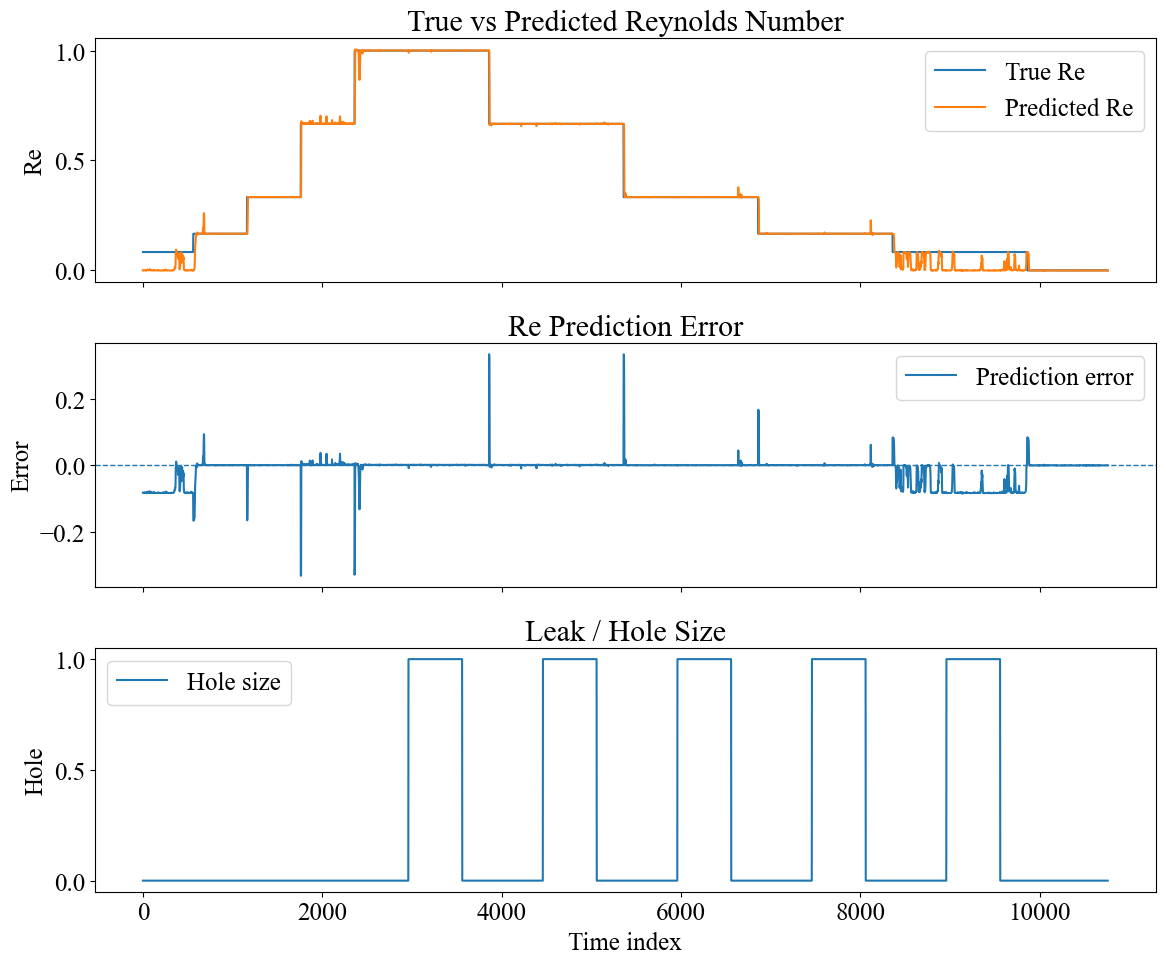

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Simple plotting code

def plot_re_diagnostics(result):
    Re_true = result["Re_true"].numpy()
    Re_pred = result["Re_pred"].numpy()
    hole = result["hole"].numpy()

    error = Re_pred - Re_true

    fig, axs = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

    axs[0].plot(Re_true, label="True Re")
    axs[0].plot(Re_pred, label="Predicted Re")
    axs[0].set_ylabel("Re")
    axs[0].set_title("True vs Predicted Reynolds Number")
    axs[0].legend()

    axs[1].plot(error, label="Prediction error")
    axs[1].axhline(0.0, linestyle="--", linewidth=1)
    axs[1].set_ylabel("Error")
    axs[1].set_title("Re Prediction Error")
    axs[1].legend()

    axs[2].plot(hole, label="Hole size")
    axs[2].set_ylabel("Hole")
    axs[2].set_xlabel("Time index")
    axs[2].set_title("Leak / Hole Size")
    axs[2].legend()

    plt.tight_layout()
    plt.show()


plot_re_diagnostics(re_results)

In [ ]:
import pandas as pd

# Save to csv

def save_re_results_to_csv(result, filename="re_predictions.csv"):
    Re_pred = result["Re_pred"].numpy()
    Re_true = result["Re_true"].numpy()

    df = pd.DataFrame({
        "datetime": result["datetime"],
        "iteration": result["iteration"][len(result["iteration"]) - len(Re_pred):],
        "Re_true": Re_true,
        "Re_pred": Re_pred,
        "Re_error": Re_pred - Re_true,
    })

    df.to_csv(filename, index=False)
    print(f"Saved to {filename}")

    return df

In [ ]:
# Save to csv (change path to desired location)

# df_re = save_re_results_to_csv(
#     re_results,
#     filename="/Users/eyeremy/Documents/GTvate_stuff/1212_1_Re_pred_val_May4.csv"
# )

Saved to /Users/eyeremy/Documents/GTvate_stuff/1212_1_Re_pred_val_May4.csv
